# Dépistage du diabète : comparer six modèles de classification

**Franck Nankeng** · Projet de machine learning supervisé · Python, scikit-learn

> *English summary — Six classifiers compared on the Pima Indians Diabetes dataset with a leakage-free pipeline
> (median imputation of hidden missing values, scaling, stratified 5-fold cross-validation). Because a missed
> diabetic patient costs more than a false alarm, the decision threshold is tuned on cross-validated
> predictions to reach a recall of at least 80 %, then checked once on the held-out test set.*

**La question métier.** Un outil de pré-dépistage doit signaler les patientes à orienter vers un test sanguin.
Rater une patiente diabétique (faux négatif) coûte bien plus cher qu'un test de confirmation inutile
(faux positif). Le bon critère n'est donc pas l'exactitude globale, mais le **rappel** sur la classe « diabétique »,
sous contrainte d'une précision acceptable.

**Ma démarche**
1. Auditer les données et repérer les valeurs manquantes déguisées en zéros.
2. Construire un pipeline sans fuite de données (imputation et normalisation apprises sur l'entraînement seulement).
3. Comparer six modèles en validation croisée stratifiée.
4. Régler le seuil de décision pour atteindre un rappel d'au moins 80 %.
5. Évaluer une seule fois sur le jeu de test, puis expliquer le modèle retenu.

*Données : Pima Indians Diabetes Database (National Institute of Diabetes and Digestive and Kidney Diseases),
768 patientes d'au moins 21 ans. Exercice construit à partir d'un cas vu en formation (cours d'IA du Pr M. Youssfi),
que j'ai entièrement restructuré et approfondi.*

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, recall_score,
                             precision_score, f1_score, accuracy_score, precision_recall_curve)
from sklearn.inspection import permutation_importance

SEED = 42
NAVY, SAFFRON, GREY = "#14213D", "#E8962E", "#8A93A6"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## 1. Audit des données

In [2]:
df = pd.read_csv("../data/diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Le résumé statistique trahit un problème : un **minimum de 0** pour la glycémie, la pression artérielle,
l'épaisseur du pli cutané, l'insuline et l'IMC. Ces valeurs sont physiologiquement impossibles :
ce sont des **valeurs manquantes codées en zéro**. Les laisser telles quelles fausserait les moyennes
et les distances utilisées par KNN ou SVM.

In [4]:
cols_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
manquants = (df[cols_zero] == 0).sum().to_frame("nb_zeros")
manquants["part_%"] = (100 * manquants["nb_zeros"] / len(df)).round(1)
manquants.sort_values("nb_zeros", ascending=False)

,nb_zeros,part_%
Insulin,374,48.7
SkinThickness,227,29.6
BloodPressure,35,4.6
BMI,11,1.4
Glucose,5,0.7


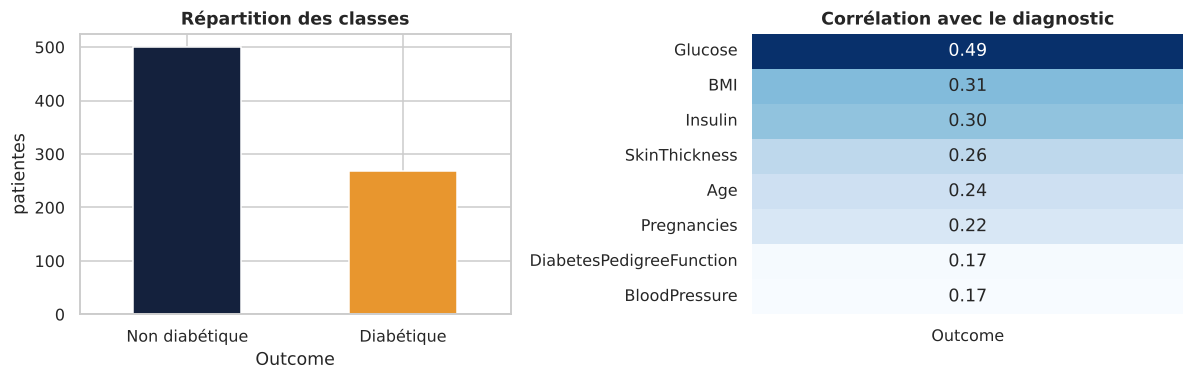

Part de diabétiques : 34.9%


In [5]:
df[cols_zero] = df[cols_zero].replace(0, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
df["Outcome"].map({0: "Non diabétique", 1: "Diabétique"}).value_counts().plot.bar(
    ax=axes[0], color=[NAVY, SAFFRON], rot=0)
axes[0].set_title("Répartition des classes"); axes[0].set_ylabel("patientes")
sns.heatmap(df.corr(numeric_only=True)[["Outcome"]].drop("Outcome").sort_values("Outcome", ascending=False),
            annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Corrélation avec le diagnostic")
plt.tight_layout(); plt.show()
print(f"Part de diabétiques : {df['Outcome'].mean():.1%}")

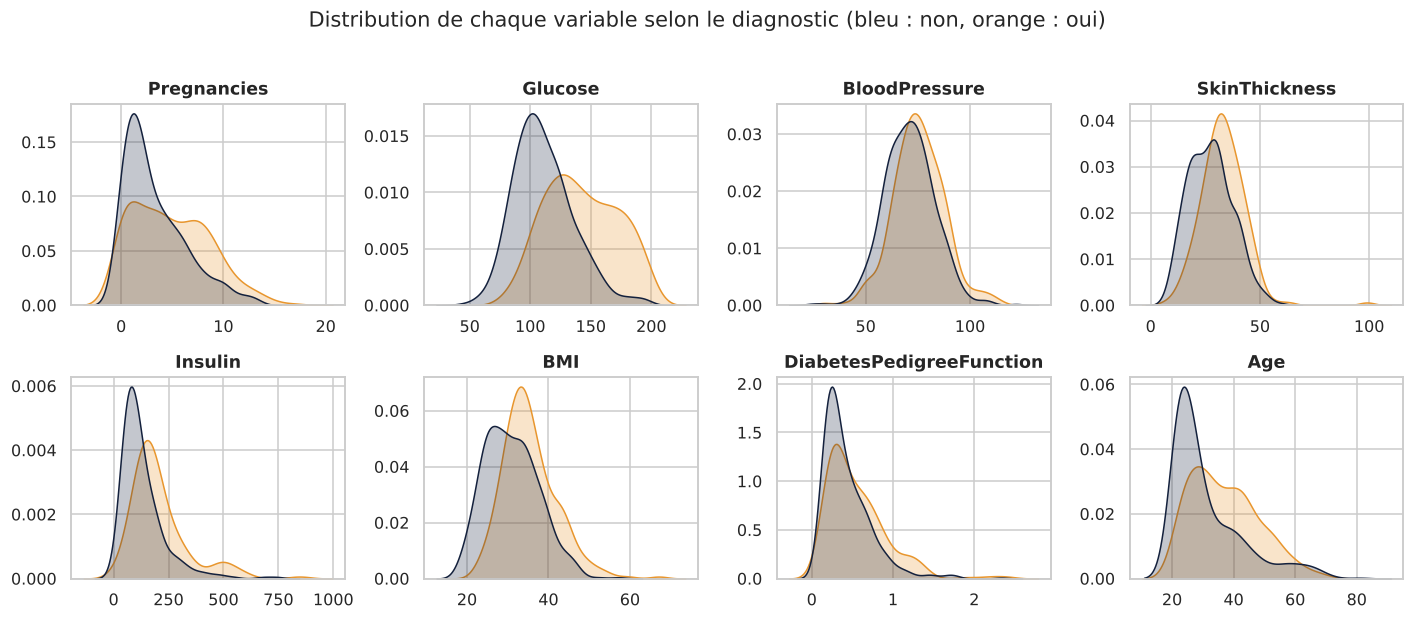

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, col in zip(axes.ravel(), df.columns.drop("Outcome")):
    sns.kdeplot(data=df, x=col, hue="Outcome", fill=True, common_norm=False,
                palette=[NAVY, SAFFRON], ax=ax, legend=False)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Distribution de chaque variable selon le diagnostic (bleu : non, orange : oui)", y=1.02)
plt.tight_layout(); plt.show()

**Ce que je retiens de l'audit**
- Les classes sont déséquilibrées (environ un tiers de diabétiques) : le découpage doit être **stratifié**
  et l'exactitude seule serait trompeuse.
- La glycémie sépare nettement les deux populations ; l'IMC et l'âge apportent un signal complémentaire.
- L'insuline est manquante pour près d'une patiente sur deux : je l'impute par la médiane, apprise sur
  l'entraînement uniquement, plutôt que de supprimer la moitié des lignes.

## 2. Découpage et pipeline sans fuite de données

In [7]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
print(f"Entraînement : {X_train.shape[0]} lignes ({y_train.mean():.1%} de diabétiques)")
print(f"Test         : {X_test.shape[0]} lignes ({y_test.mean():.1%} de diabétiques)")

def pipeline(modele):
    # Imputation et normalisation sont ré-apprises dans chaque pli de validation croisée.
    return Pipeline([("imputation", SimpleImputer(strategy="median")),
                     ("normalisation", StandardScaler()),
                     ("modele", modele)])

Entraînement : 537 lignes (34.8% de diabétiques)
Test         : 231 lignes (35.1% de diabétiques)


## 3. Six modèles en validation croisée stratifiée (5 plis)

In [8]:
modeles = {
    "Régression logistique": LogisticRegression(class_weight="balanced", max_iter=1000),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "SVM (noyau RBF)": SVC(class_weight="balanced", probability=True, random_state=SEED),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                              class_weight="balanced", random_state=SEED),
    "Perceptron multicouche": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2,
                                            max_iter=2000, random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = {"exactitude": "accuracy", "rappel": "recall", "precision": "precision",
          "f1": "f1", "auc_roc": "roc_auc"}

lignes = []
for nom, m in modeles.items():
    r = cross_validate(pipeline(m), X_train, y_train, cv=cv, scoring=scores)
    lignes.append({"modèle": nom, **{k: r[f"test_{k}"].mean() for k in scores}})
resultats = pd.DataFrame(lignes).set_index("modèle").sort_values("auc_roc", ascending=False)
resultats.style.format("{:.3f}").background_gradient(cmap="Blues", subset=["rappel", "auc_roc"])

,exactitude,rappel,precision,f1,auc_roc
modèle,,,,,
Régression logistique,0.754,0.717,0.633,0.669,0.837
Forêt aléatoire,0.752,0.728,0.630,0.673,0.830
SVM (noyau RBF),0.747,0.717,0.621,0.663,0.826
KNN (k=15),0.780,0.610,0.728,0.660,0.822
Perceptron multicouche,0.719,0.583,0.601,0.591,0.779
Arbre de décision,0.689,0.770,0.542,0.634,0.755


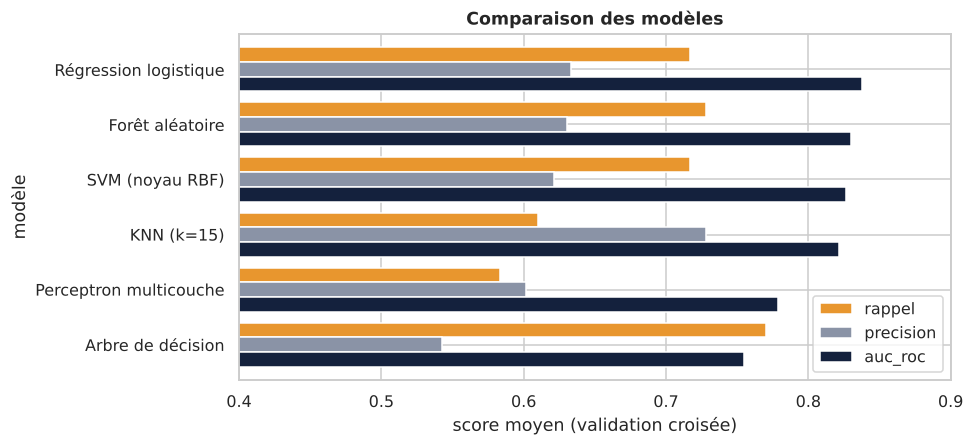

In [9]:
ax = resultats[["rappel", "precision", "auc_roc"]].plot.barh(
    figsize=(9, 4.2), color=[SAFFRON, GREY, NAVY], width=0.8)
ax.invert_yaxis(); ax.set_xlim(0.4, 0.9); ax.set_xlabel("score moyen (validation croisée)")
ax.set_title("Comparaison des modèles"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 4. Régler le seuil de décision pour le dépistage

Par défaut, un classifieur tranche à 0,5. Pour un dépistage, je préfère choisir le seuil **à partir des
prédictions de validation croisée** (jamais du jeu de test) : le seuil le plus élevé qui garantit
un rappel d'au moins 80 %, afin de garder la meilleure précision possible.

Modèle retenu : Régression logistique
Seuil retenu  : 0.413  (rappel CV 0.802, précision CV 0.577)


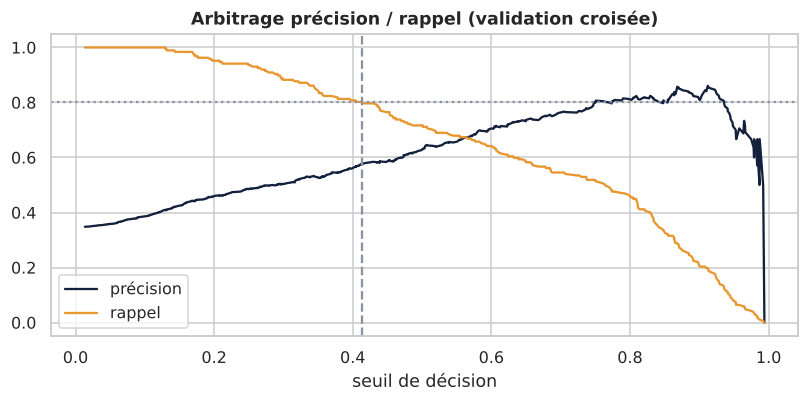

In [10]:
meilleur_nom = resultats.index[0]
meilleur = pipeline(modeles[meilleur_nom])
proba_cv = cross_val_predict(meilleur, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rapp, seuils = precision_recall_curve(y_train, proba_cv)
ok = rapp[:-1] >= 0.80
seuil = seuils[ok].max()
print(f"Modèle retenu : {meilleur_nom}")
print(f"Seuil retenu  : {seuil:.3f}  (rappel CV {rapp[:-1][ok][seuils[ok].argmax()]:.3f}, "
      f"précision CV {prec[:-1][ok][seuils[ok].argmax()]:.3f})")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(seuils, prec[:-1], color=NAVY, label="précision")
ax.plot(seuils, rapp[:-1], color=SAFFRON, label="rappel")
ax.axvline(seuil, ls="--", color=GREY); ax.axhline(0.80, ls=":", color=GREY)
ax.set_xlabel("seuil de décision"); ax.set_title("Arbitrage précision / rappel (validation croisée)")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Évaluation finale sur le jeu de test (une seule fois)

In [11]:
meilleur.fit(X_train, y_train)
proba_test = meilleur.predict_proba(X_test)[:, 1]

def bilan(seuil_dec):
    pred = (proba_test >= seuil_dec).astype(int)
    return {"seuil": round(float(seuil_dec), 3), "exactitude": accuracy_score(y_test, pred),
            "rappel": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
            "f1": f1_score(y_test, pred)}

final = pd.DataFrame([bilan(0.5), bilan(seuil)], index=["seuil par défaut (0,5)", "seuil de dépistage"])
print(f"AUC ROC sur le test : {roc_auc_score(y_test, proba_test):.3f}")
final.round(3)

AUC ROC sur le test : 0.837


,seuil,exactitude,rappel,precision,f1
"seuil par défaut (0,5)",0.500,0.762,0.704,0.648,0.675
seuil de dépistage,0.413,0.727,0.765,0.585,0.663


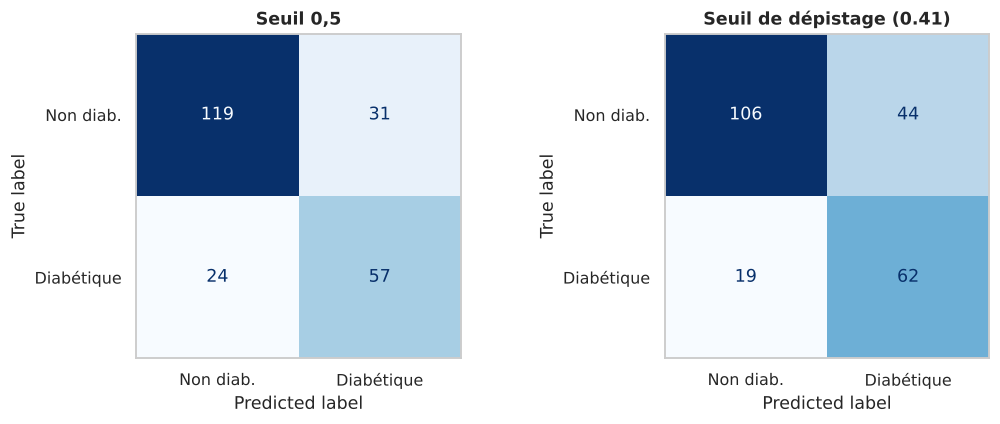

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, s, titre in zip(axes, [0.5, seuil], ["Seuil 0,5", f"Seuil de dépistage ({seuil:.2f})"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba_test >= s).astype(int)),
                           display_labels=["Non diab.", "Diabétique"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titre); ax.grid(False)
plt.tight_layout(); plt.show()

## 6. Ce qui pèse dans la décision

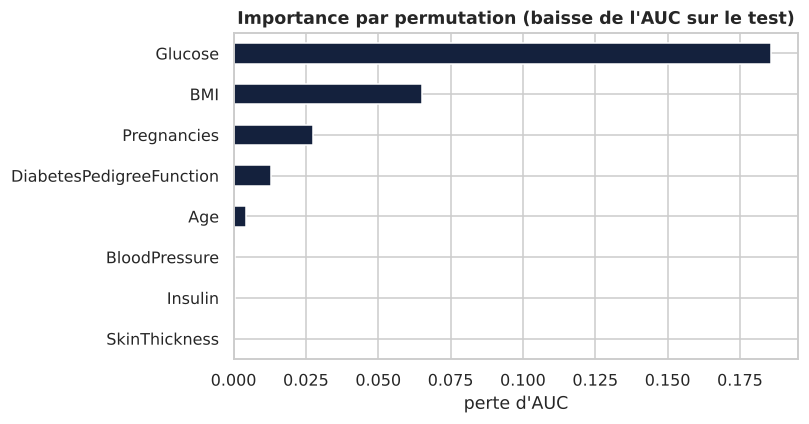

In [13]:
imp = permutation_importance(meilleur, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED)
importances = pd.Series(imp.importances_mean, index=X.columns).sort_values()
ax = importances.plot.barh(figsize=(7.5, 4), color=NAVY)
ax.set_title("Importance par permutation (baisse de l'AUC sur le test)"); ax.set_xlabel("perte d'AUC")
plt.tight_layout(); plt.show()

In [14]:
logit = pipeline(LogisticRegression(class_weight="balanced", max_iter=1000)).fit(X_train, y_train)
odds = pd.Series(np.exp(logit.named_steps["modele"].coef_[0]), index=X.columns).sort_values(ascending=False)
odds.to_frame("rapport de cotes pour +1 écart-type").round(2)

,rapport de cotes pour +1 écart-type
Glucose,3.10
BMI,2.14
Pregnancies,1.59
DiabetesPedigreeFunction,1.31
Age,1.14
BloodPressure,0.98
Insulin,0.98
SkinThickness,0.90


## 7. Conclusions

**Résultats**
- La **régression logistique** obtient la meilleure AUC en validation croisée (0,837), devant la forêt aléatoire (0,830)
  et le SVM (0,826). Le modèle le plus simple est aussi le plus performant et le plus explicable : c'est lui que je retiens.
- **KNN a la meilleure exactitude (0,780) mais un rappel de 0,610** : il rate quatre diabétiques sur dix. C'est l'exemple
  type d'une métrique flatteuse qui conduirait à choisir le mauvais modèle pour ce besoin.
- Sur le jeu de test (231 patientes dont 81 diabétiques), l'AUC reste à **0,837**, comme en validation croisée :
  le modèle généralise sans sur-apprentissage.
- Abaisser le seuil de 0,50 à 0,41 permet de détecter **62 diabétiques au lieu de 57** (rappel de 70,4 % à 76,5 %),
  au prix de 13 fausses alertes supplémentaires (31 à 44). Pour un pré-dépistage suivi d'un test sanguin, cet arbitrage est le bon.
- Le rappel sur le test (76,5 %) reste un peu sous l'objectif de 80 % atteint en validation croisée : avec 81 cas positifs,
  l'écart représente trois patientes. Je ne réajuste pas le seuil sur le test, ce qui reviendrait à tricher ;
  je le confirmerais sur un échantillon plus large.
- La **glycémie** pèse le plus (risque multiplié par 3,1 par écart-type), suivie de l'**IMC** (2,1) et du **nombre de grossesses** (1,6),
  ce qui est cohérent avec les facteurs de risque connus.

**Limites et suites**
- 768 patientes issues d'une population spécifique : le modèle n'est pas transposable tel quel et ne constitue pas un dispositif médical.
- Pistes d'amélioration : imputation multivariée (`IterativeImputer`), calibration des probabilités, et choix du seuil
  à partir d'un coût explicite des faux négatifs et des faux positifs défini avec les métiers.